# Разработка A/B-тестирования и анализ результатов

Вы работаете продуктовым аналитиком в компании, которая разрабатывает развлекательное приложение с функцией «бесконечной» ленты, как, например, в приложениях с короткими видео. В вашем приложении существует две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

Команда разработчиков рекомендательных систем создала новый алгоритм рекомендаций, который, по их мнению, будет показывать более интересный контент для каждого пользователя. Вас, как аналитика, просят помочь рассчитать параметры A/B-теста, который позволит проверить эту гипотезу, и проанализировать его результаты.

## Описание данных

Вы будете работать с тремя таблицами:

- `sessions_project_history.csv` — таблица с историческими данными по сессиям пользователей на период с 2025-08-15 по 2025-09-23. Путь к файлу: `/datasets/sessions_project_history.csv`.

- `sessions_project_test_part.csv` — таблица с данными за первый день проведения A/B-теста, то есть за 2025-10-14. Путь к файлу: `/datasets/sessions_project_test_part.csv`.

- `sessions_project_test.csv` — таблица с данными за весь период проведения A/B-теста, то есть с 2025-10-14 по 2025-11-02. Путь к файлу: `/datasets/sessions_project_test.csv`.

У этих таблиц почти совпадает структура и содержание колонок, различаются лишь периоды наблюдения.

Поля таблиц `sessions_project_history.csv`, `sessions_project_test.csv`, `sessions_project_test_part.csv`:

- `user_id` — идентификатор пользователя;

- `session_id` — идентификатор сессии в приложении;

- `session_date` — дата сессии;

- `session_start_ts` — дата и время начала сессии;

- `install_date` — дата установки приложения;

- `session_number` — порядковый номер сессии для конкретного пользователя;

- `registration_flag` — является ли пользователь зарегистрированным;

- `page_counter` — количество просмотренных страниц во время сессии;

- `region` — регион пользователя;

- `device` — тип устройства пользователя;

- `test_group` — тестовая группа (в таблице с историческими данными этого столбца нет).


## Подготовка
Рассчитать параметры теста, оценить корректность его проведения и проанализировать результаты эксперимента.

### Работа с историческими данными (EDA)

#### Загрузка исторических данных
Импортируем библиотеки.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from math import ceil
from scipy.stats import ttest_ind

Считываем и сохраняем в датафрейм `sessions_history` CSV-файл с историческими данными о сессиях пользователей `sessions_project_history.csv`.

In [2]:
sessions_history = pd.read_csv('/datasets/sessions_project_history.csv') 

Выводим первые пять строк полученного датафрейма и информацию по нему.

In [3]:
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


In [4]:
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            435924 non-null  object
 1   session_id         435924 non-null  object
 2   session_date       435924 non-null  object
 3   session_start_ts   435924 non-null  object
 4   install_date       435924 non-null  object
 5   session_number     435924 non-null  int64 
 6   registration_flag  435924 non-null  int64 
 7   page_counter       435924 non-null  int64 
 8   region             435924 non-null  object
 9   device             435924 non-null  object
dtypes: int64(3), object(7)
memory usage: 33.3+ MB


Пропусков нет, поменяем тип данных в поле `session_start_ts`.

In [5]:
sessions_history['session_start_ts'] = pd.to_datetime(sessions_history['session_start_ts'])

In [6]:
sessions_history['device'].value_counts()

Android    195644
PC         109301
iPhone      87020
Mac         43959
Name: device, dtype: int64

Больше всего пользователей `Android`.

In [7]:
sessions_history['region'].value_counts()

CIS     195975
MENA    175626
EU       64323
Name: region, dtype: int64

In [8]:
sessions_history['install_date'].min()

'2025-08-11'

In [9]:
sessions_history['install_date'].max()

'2025-09-10'

In [10]:
sessions_history['session_date'].min()

'2025-08-11'

In [11]:
sessions_history['session_date'].max()

'2025-09-23'

Всё как в описании таблицы.

In [12]:
sessions_history['session_number'].value_counts()

1     134039
2     124453
3      94201
4      53164
5      21799
6       6583
7       1442
8        213
9         28
10         2
Name: session_number, dtype: int64

После двух сессий начсинается резкий спад, 10 набирают только два пользователя.

In [13]:
sessions_history[sessions_history['session_number'] == 10]

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android
425805,6A73CB5566BB494D,84A3DC0CFF449F53,2025-09-09,2025-09-09 16:36:04,2025-08-28,10,1,1,MENA,Mac


In [14]:
sessions_history['registration_flag'].value_counts()

0    402216
1     33708
Name: registration_flag, dtype: int64

Большая часть пользователей не зарегестрирована.

In [15]:
sessions_history['registration_flag'].value_counts(normalize=True)

0    0.922675
1    0.077325
Name: registration_flag, dtype: float64

In [16]:
sessions_history['page_counter'].value_counts(sort=False)

1     29160
2    105536
3    166690
4    105569
5     26288
6      2589
7        92
Name: page_counter, dtype: int64

In [17]:
sessions_history.duplicated().sum() 

0

In [18]:
sessions_history.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android


In [19]:
sessions_history.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 435924 entries, 0 to 435923
Data columns (total 10 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   user_id            435924 non-null  object        
 1   session_id         435924 non-null  object        
 2   session_date       435924 non-null  object        
 3   session_start_ts   435924 non-null  datetime64[ns]
 4   install_date       435924 non-null  object        
 5   session_number     435924 non-null  int64         
 6   registration_flag  435924 non-null  int64         
 7   page_counter       435924 non-null  int64         
 8   region             435924 non-null  object        
 9   device             435924 non-null  object        
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 33.3+ MB


#### Знакомство с данными
Для каждого уникального пользователя `user_id` рассчитаем количество уникальных сессий `session_id`.

In [20]:
user_id_sessions_history = sessions_history.groupby('user_id')['session_id'].nunique().reset_index(name = 'session_count')
user_id_sessions_history

,user_id,session_count
0,00005FB6A13A6FBE,2
1,0000B15A18D77ED9,3
2,0000C4E3A4A571A9,2
3,000293FAF9E67A81,4
4,00029C5AE889A6C3,2
...,...,...
134034,FFFCDE7746148710,4
134035,FFFDD413285E753F,3
134036,FFFECBA0F2578AB0,2
134037,FFFEDB68228B5F21,5


Выведем на экран все данные из таблицы `sessions_history` для одного пользователя с наибольшим количеством сессий (всего пользователей с максимальным количеством два - по 10 сессий).

In [21]:
max_sessions_user_id = user_id_sessions_history.loc[user_id_sessions_history['session_count'].idxmax(), 'user_id']
max_sessions_user_id

'10E0DEFC1ABDBBE0'

In [22]:
max_sessions_history_user_id = sessions_history[sessions_history['user_id'] == max_sessions_user_id]
max_sessions_history_user_id

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
115558,10E0DEFC1ABDBBE0,B8F0423BBFFCF5DC,2025-08-14,2025-08-14 13:57:39,2025-08-14,1,0,4,CIS,Android
191751,10E0DEFC1ABDBBE0,87CA2FA549473837,2025-08-15,2025-08-15 16:42:10,2025-08-14,2,0,3,CIS,Android
239370,10E0DEFC1ABDBBE0,4ADD8011DCDCE318,2025-08-16,2025-08-16 19:53:21,2025-08-14,3,0,3,CIS,Android
274629,10E0DEFC1ABDBBE0,DF0FD0E09BF1F3D7,2025-08-17,2025-08-17 15:03:43,2025-08-14,4,0,1,CIS,Android
302501,10E0DEFC1ABDBBE0,3C221774B4DE6885,2025-08-18,2025-08-18 17:29:14,2025-08-14,5,0,4,CIS,Android
325557,10E0DEFC1ABDBBE0,031BD7A67048105B,2025-08-19,2025-08-19 13:23:55,2025-08-14,6,0,2,CIS,Android
345336,10E0DEFC1ABDBBE0,FF4315CF4AD4B100,2025-08-20,2025-08-20 19:31:54,2025-08-14,7,0,2,CIS,Android
377532,10E0DEFC1ABDBBE0,4045FEA0747203B4,2025-08-22,2025-08-22 17:54:13,2025-08-14,8,0,2,CIS,Android
403538,10E0DEFC1ABDBBE0,344B086C421C7F37,2025-08-24,2025-08-24 14:46:13,2025-08-14,9,0,2,CIS,Android
414743,10E0DEFC1ABDBBE0,054F20BA371E4C9D,2025-08-25,2025-08-25 18:36:41,2025-08-14,10,0,3,CIS,Android


Изучим таблицу для одного пользователя, чтобы лучше понять логику формирования каждого столбца данных.

In [23]:
max_sessions_history_user_id.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 10 entries, 115558 to 414743
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            10 non-null     object        
 1   session_id         10 non-null     object        
 2   session_date       10 non-null     object        
 3   session_start_ts   10 non-null     datetime64[ns]
 4   install_date       10 non-null     object        
 5   session_number     10 non-null     int64         
 6   registration_flag  10 non-null     int64         
 7   page_counter       10 non-null     int64         
 8   region             10 non-null     object        
 9   device             10 non-null     object        
dtypes: datetime64[ns](1), int64(3), object(6)
memory usage: 880.0+ bytes


Активность просмотра страниц низкая, хотя сессий больше всего.

In [24]:
max_sessions_history_user_id.describe()

,session_number,registration_flag,page_counter
count,10.00000,10.0,10.000000
mean,5.50000,0.0,2.600000
std,3.02765,0.0,0.966092
min,1.00000,0.0,1.000000
25%,3.25000,0.0,2.000000
50%,5.50000,0.0,2.500000
75%,7.75000,0.0,3.000000
max,10.00000,0.0,4.000000


#### Анализ числа регистраций
Одна из важнейших метрик продукта — число зарегистрированных пользователей. Используя исторические данные, визуализируем, как менялось число регистраций в приложении за время его существования. Пользователь считается зарегистрированным только в день совершения регистрации. Таким образом, необходимо проанализировать количество зарегистрированных активных пользователей за каждый день без накопления (аналог DAU, но для регистраций пользователей).

Агрегируем исторические данные и рассчитаем число уникальных пользователей и число зарегистрированных пользователей для каждого дня наблюдения. Для простоты считаем, что у пользователя в течение дня бывает одна сессия максимум и статус регистрации в течение одного дня не может измениться.

In [25]:
day_reg_users = (
    sessions_history.groupby('session_date')
    .agg(users = ('user_id', 'nunique'), reg = ('registration_flag', 'sum'))
    .reset_index())
day_reg_users['part'] = round(day_reg_users['reg']/day_reg_users['users'], 3)
day_reg_users

,session_date,users,reg,part
0,2025-08-11,3919,169,0.043
1,2025-08-12,6056,336,0.055
2,2025-08-13,8489,464,0.055
3,2025-08-14,10321,625,0.061
4,2025-08-15,14065,840,0.060
5,2025-08-16,12205,916,0.075
6,2025-08-17,11200,833,0.074
7,2025-08-18,10839,860,0.079
8,2025-08-19,12118,831,0.069
9,2025-08-20,13514,1008,0.075


Построим линейные графики общего числа пользователей и общего числа зарегистрированных пользователей по дням. Отобразим их на одном графике.

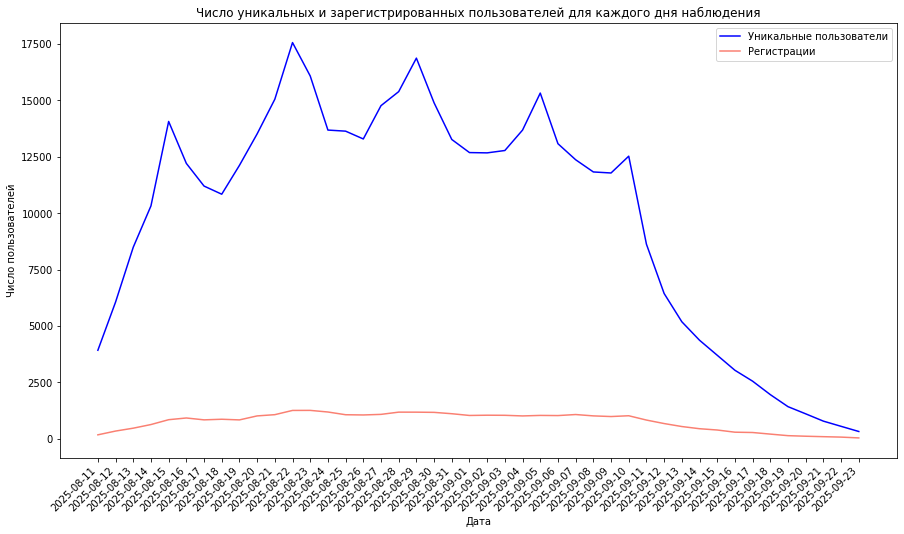

In [26]:
plt.figure(figsize=(15, 8))

plt.plot(
    day_reg_users['session_date'],
    day_reg_users['users'],
    marker = '',
    label = 'Уникальные пользователи',
    color = 'blue'
)

plt.plot(
    day_reg_users['session_date'],
    day_reg_users['reg'],
    marker = '',
    label = 'Регистрации',
    color = 'salmon'
)

plt.title('Число уникальных и зарегистрированных пользователей для каждого дня наблюдения')
plt.xlabel('Дата')
plt.ylabel('Число пользователей')

plt.xticks(rotation=45, ha='right')
plt.legend()
plt.show()

Построим отдельный линейный график доли зарегистрированных пользователей от всех пользователей по дням.

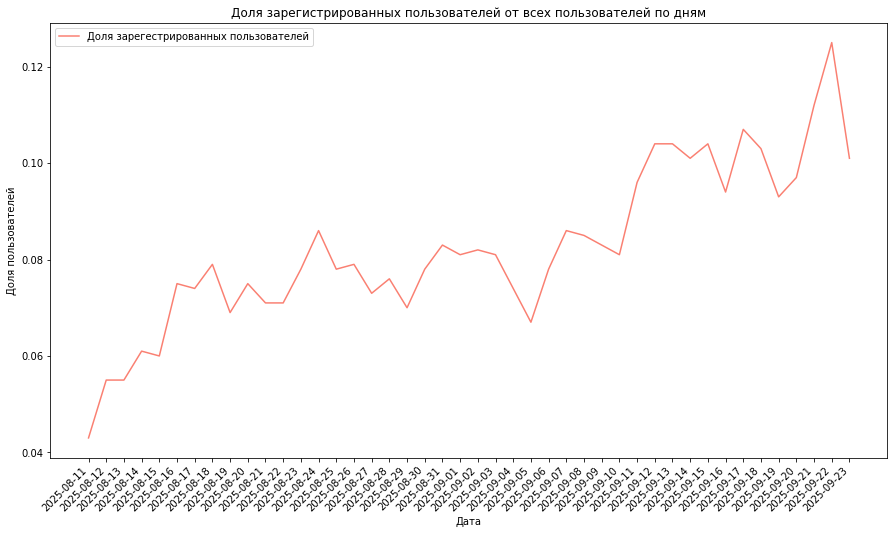

In [27]:
plt.figure(figsize=(15, 8))

plt.plot(
    day_reg_users['session_date'],
    day_reg_users['part'],
    marker = '',
    label = 'Доля зарегестрированных пользователей',
    color = 'salmon'
)

plt.title('Доля зарегистрированных пользователей от всех пользователей по дням')
plt.xlabel('Дата')
plt.ylabel('Доля пользователей')

plt.xticks(rotation=45, ha='right')
plt.legend()
plt.show()

Доля зарегестрированных пользователей со временем, хоть и не плавно, растёт с 4% до 12% на пике. В конце графика резкий подъём начиная с 11 сентября, что сходится в графиком выше. Под двум графикам видим, что количество регистраций небольшое относительно количества пользователей, их пики не совпадают. Дневной рост регистраций с положительной динамикой, но происходит на фоне снижения аудитории.

#### Анализ числа просмотренных страниц
Другая важная метрика продукта — число просмотренных страниц в приложении. Чем больше страниц просмотрено, тем сильнее пользователь увлечён контентом, а значит, выше шансы, что он зарегистрируется и оплатит подписку.

Проанализируем число просмотренных страниц во время первых сессий пользователей. Найдём количество первых сессий для каждого значения количества просмотренных страниц. Например: одну страницу просмотрели в 8978 первых сессиях, две страницы — в 32 494 первых сессиях и так далее.

In [28]:
page_counter_sessions = sessions_history[sessions_history['session_number'] == 1]
page_counter_sessions

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android
...,...,...,...,...,...,...,...,...,...,...
134034,DE4301D8D1AED746,429B1FEC78B893BC,2025-09-04,2025-09-04 18:23:43,2025-09-04,1,0,3,MENA,Android
134035,28944BBC6F568818,15C6C97D6FEFC2E6,2025-09-04,2025-09-04 14:16:33,2025-09-04,1,0,3,MENA,Android
134036,9608517F92C28B33,9363CFAA42D87E60,2025-09-04,2025-09-04 17:02:24,2025-09-04,1,0,3,MENA,PC
134037,3586AB0D05E4B6AC,5C0AFDEA71780240,2025-09-04,2025-09-04 11:48:45,2025-09-04,1,0,2,EU,PC


In [29]:
page_counter_sessions = page_counter_sessions['page_counter'].value_counts().sort_index()
page_counter_sessions

1     8978
2    32494
3    50939
4    32739
5     8075
6      777
7       37
Name: page_counter, dtype: int64

Построим столбчатую диаграмму, где по оси X будет число просмотренных страниц, по оси Y — количество сессий.

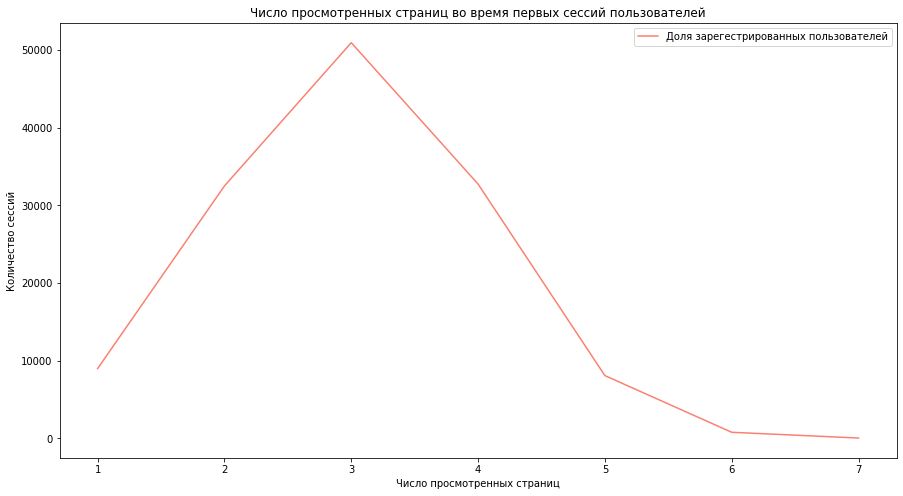

In [30]:
plt.figure(figsize=(15, 8))

plt.plot(
    page_counter_sessions.index,
    page_counter_sessions.values,
    marker = '',
    label = 'Доля зарегестрированных пользователей',
    color = 'salmon'
)

plt.title('Число просмотренных страниц во время первых сессий пользователей')
plt.xlabel('Число просмотренных страниц')
plt.ylabel('Количество сессий')

plt.legend()
plt.show()

Пик приходится на 3 страницы, дальше количество сессий начинает резко падать, после 6 линия пологая, а больше 7 страниц во время первой сессии пользователи не смотрят. 

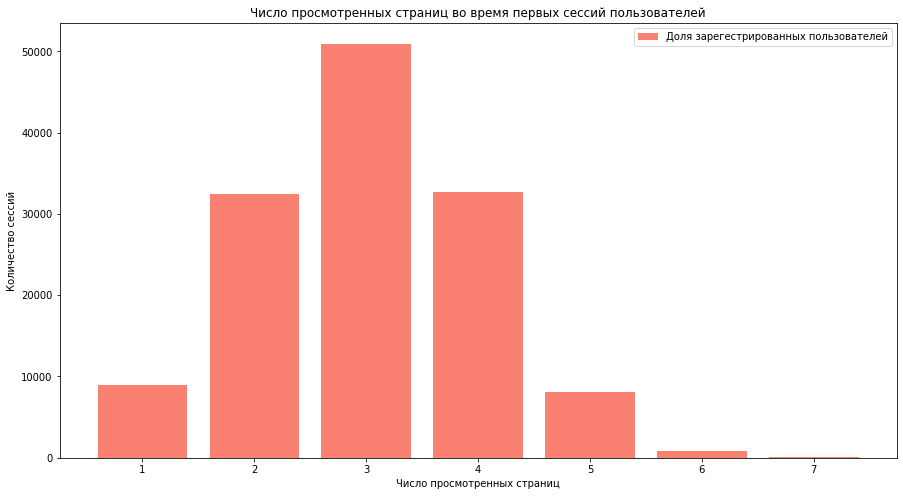

In [31]:
plt.figure(figsize=(15, 8))

plt.bar(
    page_counter_sessions.index,
    page_counter_sessions.values,
    label = 'Доля зарегестрированных пользователей',
    color = 'salmon'
)

plt.title('Число просмотренных страниц во время первых сессий пользователей')
plt.xlabel('Число просмотренных страниц')
plt.ylabel('Количество сессий')

plt.legend()
plt.show()

#### Доля пользователей, просмотревших более четырёх страниц
Продуктовая команда продукта считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций. Этот показатель является важной прокси-метрикой для продукта.

В датафрейме `sessions_history` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если было просмотрено меньше.

In [32]:
sessions_history['good_session'] = (sessions_history['page_counter'] > 3).astype(int)
sessions_history

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,good_session
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone,0
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android,1
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC,1
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android,1
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android,0
...,...,...,...,...,...,...,...,...,...,...,...
435919,769BC199AF26FEF8,914903B51D69C5EA,2025-09-17,2025-09-17 21:33:57,2025-09-04,3,1,3,CIS,PC,0
435920,599DED39F3CD2ADE,66ADBE343C94DCDA,2025-09-17,2025-09-17 17:11:46,2025-09-04,4,0,4,MENA,iPhone,1
435921,1FA20C4BC94E64B2,C4CCD7E81733665F,2025-09-17,2025-09-17 19:36:55,2025-09-04,4,0,4,CIS,Android,1
435922,88E5FC3016A7A0AD,6834FB4914B56200,2025-09-17,2025-09-17 22:13:33,2025-09-04,5,0,4,MENA,PC,1


In [33]:
page_counter_sessions_2 = sessions_history[sessions_history['session_number'] == 1]
page_counter_sessions_2.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,good_session
0,E302123B7000BFE4,F9AF61A0C2023832,2025-08-15,2025-08-15 17:47:35,2025-08-15,1,0,3,CIS,iPhone,0
1,2530F72E221829FB,85003A206CBDAC6F,2025-08-15,2025-08-15 16:42:14,2025-08-15,1,0,4,MENA,Android,1
2,876E020A4FC512F5,3677423E49D72DEE,2025-08-15,2025-08-15 12:30:00,2025-08-15,1,0,4,EU,PC,1
3,2640B349E1D81584,956B45F5915CA225,2025-08-15,2025-08-15 15:31:31,2025-08-15,1,0,4,CIS,Android,1
4,94E1CBFAEF1F5EE9,83BF0DA35F9F1F40,2025-08-15,2025-08-15 21:33:53,2025-08-15,1,0,3,CIS,Android,0


In [34]:
day_good_session = (
    page_counter_sessions_2.groupby('session_date')
    .agg(total = ('session_id', 'count'), good = ('good_session', 'sum'))
    .reset_index())
day_good_session['good_part'] = round(day_good_session['good']/day_good_session['total'], 3)
day_good_session

,session_date,total,good,good_part
0,2025-08-11,3919,1226,0.313
1,2025-08-12,4106,1225,0.298
2,2025-08-13,5087,1561,0.307
3,2025-08-14,5456,1741,0.319
4,2025-08-15,7801,2427,0.311
5,2025-08-16,3787,1168,0.308
6,2025-08-17,2978,951,0.319
7,2025-08-18,3079,964,0.313
8,2025-08-19,4412,1387,0.314
9,2025-08-20,5215,1612,0.309


Построим график со средним значением доли успешных первых сессий от всех первых сессий пользователей. Данные визуализируем по дням за весь период наблюдения.

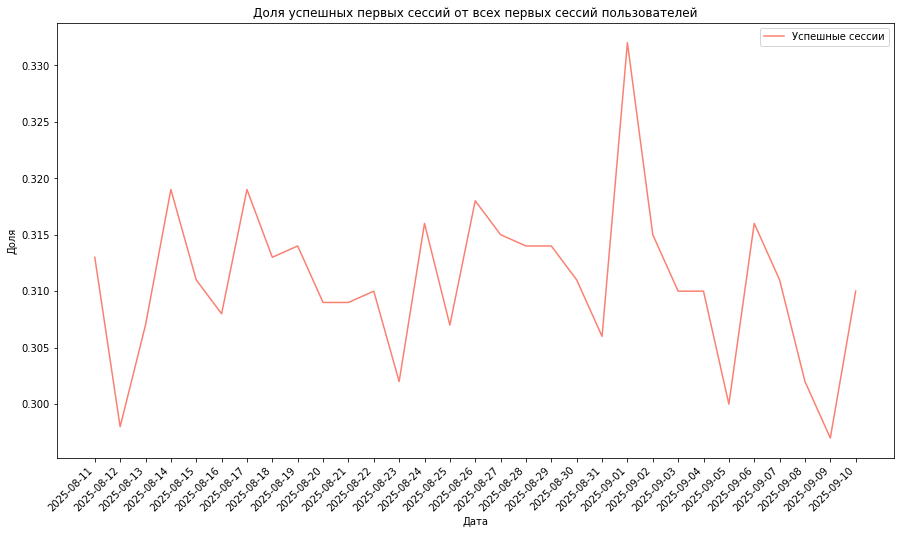

In [35]:
plt.figure(figsize=(15, 8))

plt.plot(
    day_good_session['session_date'],
    day_good_session['good_part'],
    marker = '',
    label = 'Успешные сессии',
    color = 'salmon'
)

plt.title('Доля успешных первых сессий от всех первых сессий пользователей')
plt.xlabel('Дата')
plt.ylabel('Доля')

plt.xticks(rotation=45, ha='right')
plt.legend()
plt.show()

Доля просмотра 4х страниц и более в рамках первой сесии стабильно держится на уровне 30-32%. Есть относительно высокий пик 1 сентября, хотя в целом пики и падения распределены равномерно.

### Подготовка к тесту
При планировании теста необходимо проделать несколько важных шагов:

- Определиться с целевой метрикой

- Рассчитать необходимый размер выборки

- Исходя из текущих значений трафика рассчитать необходимую длительность проведения теста

#### Расчёт размера выборки
Рассчитаем необходимое для эксперимента количество пользователей.

Параметры:

- Уровень значимости — 0.05

- Вероятность ошибки второго рода — 0.2

- Мощность теста

- Минимальный детектируемый эффект, или MDE, — 3%

При расчёте размера выборки используем метод `solve_power()` из класса `power.NormalIndPower` модуля `statsmodels.stats`.

In [36]:
# Задайте параметры:
alpha = 0.05
beta = 0.2
power = 0.8
p = 0.3 # Базовый уровень доли
mde = p * 0.03
effect_size = proportion_effectsize(p, p + mde)

# Инициализируем класс NormalIndPower
power_analysis = NormalIndPower()

# Расчёт размера выборки
sample_size = power_analysis.solve_power(
    effect_size = effect_size,
    power = power,
    alpha = alpha,
    ratio = 1 # Равномерное распределение выборок
)

print(f"Необходимый размер выборки для каждой группы: {int(sample_size)}")

Необходимый размер выборки для каждой группы: 41040


При заданных параметрах общий объём выборки - 82080. MDE очень маленький, так что выборка должна быть большая.

#### Расчёт длительности A/B-теста

Используем данные о количестве пользователей в каждой выборке и среднем количестве пользователей приложения. 

Рассчитаем длительность теста:

- Вычислим среднее количество уникальных пользователей приложения в день

- Определим длительность теста исходя из рассчитанного значения размера выборок и среднего дневного трафика приложения. Количество дней округлим в большую сторону

In [37]:
# Среднее количество пользователей приложения в день по историческим данным
avg_daily_users = round(sessions_history.groupby('session_date')['user_id'].nunique().mean())

# Рассчитываем длительность теста в днях как отношение размера выборки к среднему числу пользователей
test_duration = ceil((sample_size * 2) / avg_daily_users)

print(f"Рассчитанная длительность A/B-теста при текущем уровене трафика в {avg_daily_users} пользователей в день составит {test_duration} дней")

Рассчитанная длительность A/B-теста при текущем уровене трафика в 9907 пользователей в день составит 9 дней


В результате подготовки к тесту определили:

- Размер выборки для одной группы – 41040
- Общий размер выборки – 82080
- Уровень трафика в день – 9907
- Длительность теста – 9 дней

## Мониторинг А/В-теста

### Проверка распределения пользователей

A/B-тест успешно запущен, и уже доступны данные за первые три дня. На этом этапе нужно убедиться, что всё идёт хорошо: пользователи разделены правильным образом, а интересующие вас метрики корректно считаются.

Считываем и сохраняем в датафрейм `sessions_test_part` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test_part.csv`.

In [38]:
sessions_test_part = pd.read_csv('/datasets/sessions_project_test_part.csv')
sessions_test_part.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,3404844B53442747,B4901323BD537E45,2025-10-14,2025-10-14 19:28:49,2025-10-14,1,0,3,CIS,Android,B
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
4,37E0CE723AE568E0,2E6ED45E8C86C4E9,2025-10-14,2025-10-14 15:39:44,2025-10-14,1,0,3,CIS,Mac,B


In [39]:
sessions_test_part.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3130 entries, 0 to 3129
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            3130 non-null   object
 1   session_id         3130 non-null   object
 2   session_date       3130 non-null   object
 3   session_start_ts   3130 non-null   object
 4   install_date       3130 non-null   object
 5   session_number     3130 non-null   int64 
 6   registration_flag  3130 non-null   int64 
 7   page_counter       3130 non-null   int64 
 8   region             3130 non-null   object
 9   device             3130 non-null   object
 10  test_group         3130 non-null   object
dtypes: int64(3), object(8)
memory usage: 269.1+ KB


Рассчитываем количество уникальных пользователей в каждой из экспериментальных групп для одного дня наблюдения.

In [40]:
test_group = sessions_test_part.groupby('test_group')['user_id'].nunique()
test_group

test_group
A    1477
B    1466
Name: user_id, dtype: int64

Рассчитываем и выводим на экран процентную разницу в количестве пользователей в группах A и B. Построим визуализацию, на которой будет видно возможное различие двух групп.

Для расчёта процентной разницы воспользуемся формулой:
$$P = 100 \cdot  \frac{|A − B|}{A}$$

In [41]:
test_group_A = test_group['A']
test_group_B = test_group['B']

In [42]:
test_group_A

1477

In [43]:
test_group_B

1466

In [44]:
P = round(100 * abs(test_group_A - test_group_B) / test_group_A, 2)
P

0.74

Разница между группами меньше процента. Всего 11 человек

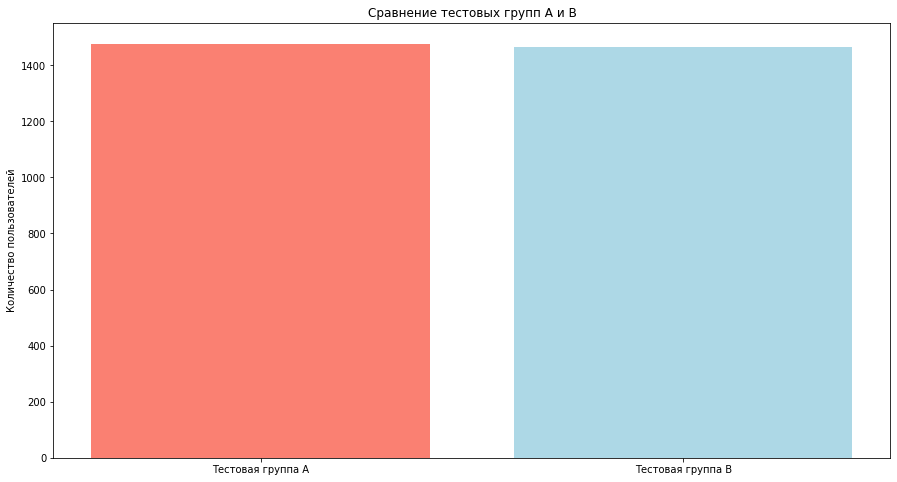

In [45]:
plt.figure(figsize=(15, 8))

plt.bar(
    ['Тестовая группа A', 'Тестовая группа B'],
    [test_group['A'],test_group['B']],
    color = ['salmon', 'lightblue']
)

plt.title('Сравнение тестовых групп A и B')
plt.ylabel('Количество пользователей')

plt.show()

### Проверка пересечений пользователей
Помимо проверки равенства количества пользователей в группах, полезно убедиться в том, что группы независимы. Для этого нужно убедиться, что никто из пользователей случайно не попал в обе группы одновременно.

Рассчитаем количество пользователей, которые встречаются одновременно в группах A и B, или убедимся, что таких нет.

In [46]:
test_group_A_int = sessions_test_part[sessions_test_part['test_group'] == 'A']['user_id']
test_group_B_int = sessions_test_part[sessions_test_part['test_group'] == 'B']['user_id']

intersection = list(set(test_group_A_int) & set(test_group_B_int))
intersection

[]

Общих пользователей нет

In [47]:
users_dub = sessions_test_part.groupby('user_id')['test_group'].nunique()
users_dub = users_dub[users_dub == 2]
users_dub

Series([], Name: test_group, dtype: int64)

### Равномерность разделения пользователей по устройствам
Полезно также убедиться в том, что пользователи равномерно распределены по всем доступным категориальным переменным — типам устройств и регионам.

Построим две диаграммы:
- доля каждого типа устройства для пользователей из группы A
- доля каждого типа устройства для пользователей из группы B

In [48]:
test_group_A = sessions_test_part[sessions_test_part['test_group'] == 'A']
test_group_B = sessions_test_part[sessions_test_part['test_group'] == 'B']

In [49]:
test_group_A

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
1,3A2BF4D364E62D89,216FC619308F8788,2025-10-14,2025-10-14 21:11:04,2025-10-14,1,0,3,MENA,iPhone,A
2,79CDAE11E32B1597,EDFCE4AC1A504074,2025-10-14,2025-10-14 21:44:03,2025-10-14,1,0,3,CIS,iPhone,A
3,D6AF8D78297A931F,CF0AC0EEDE92C690,2025-10-14,2025-10-14 19:07:55,2025-10-14,1,0,4,CIS,PC,A
5,4190F73B64AC08F3,0C1548A468743268,2025-10-14,2025-10-14 16:31:56,2025-10-14,1,0,3,CIS,Mac,A
8,ED7534C2405ECF15,1E87592C2F8108A9,2025-10-14,2025-10-14 21:10:14,2025-10-14,1,0,2,CIS,PC,A
...,...,...,...,...,...,...,...,...,...,...,...
3117,13106643179D812C,BB59A6F7F56BDFC6,2025-10-14,2025-10-14 18:57:04,2025-10-14,1,0,4,CIS,Android,A
3118,E3ECD926CCCA5DD6,0798E4809A508A8F,2025-10-14,2025-10-14 14:58:48,2025-10-14,1,0,3,MENA,Android,A
3119,4350201F7EB53804,6F0576280FF5020D,2025-10-14,2025-10-14 20:55:19,2025-10-14,1,0,1,MENA,Android,A
3123,FCABF659AF37BDAC,B6665B288E7ED989,2025-10-14,2025-10-14 14:00:07,2025-10-14,1,0,4,CIS,Android,A


In [50]:
test_group_A_users = test_group_A.drop_duplicates(subset = ['user_id'])
test_group_B_users = test_group_B.drop_duplicates(subset = ['user_id'])

In [51]:
test_group_A_dev = test_group_A_users['device'].value_counts()
test_group_A_dev

Android    656
PC         369
iPhone     296
Mac        156
Name: device, dtype: int64

In [52]:
test_group_B_dev = test_group_B_users['device'].value_counts()
test_group_B_dev

Android    668
PC         381
iPhone     269
Mac        148
Name: device, dtype: int64

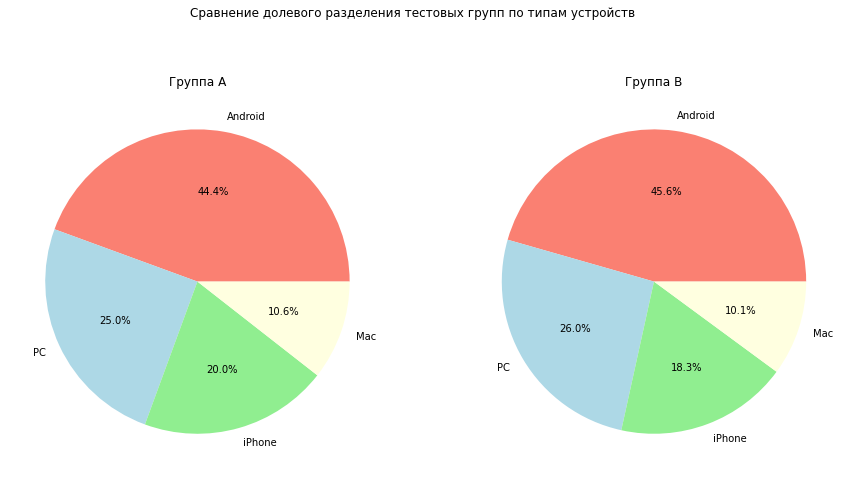

In [53]:
fig, (A, B) = plt.subplots(1, 2, figsize=(15, 8))

A.pie(
    test_group_A_dev,
    labels = test_group_A_dev.index,
    autopct='%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen', 'lightyellow']
)

B.pie(
    test_group_B_dev,
    labels = test_group_B_dev.index,
    autopct='%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen', 'lightyellow']
)

plt.suptitle('Сравнение долевого разделения тестовых групп по типам устройств')
A.set_title('Группа A')
B.set_title('Группа B')

plt.show()

Расхождения в долях устройств минимальное, в группе A больше пользователей платформы `iPhone`, в группе `Mac`.

### Равномерность распределения пользователей по регионам
Теперь убедимся, что пользователи равномерно распределены по регионам.

Построим две диаграммы:

- доля каждого региона для пользователей из группы A

- доля каждого региона для пользователей из группы B

In [54]:
test_group_A_reg = test_group_A_users['region'].value_counts()
test_group_A_reg

CIS     644
MENA    609
EU      224
Name: region, dtype: int64

In [55]:
test_group_B_reg = test_group_B_users['region'].value_counts()
test_group_B_reg

CIS     645
MENA    604
EU      217
Name: region, dtype: int64

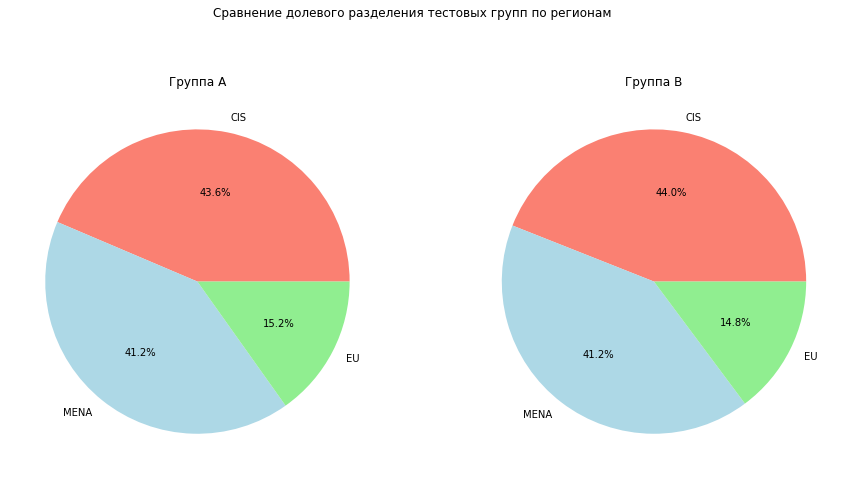

In [56]:
fig, (A, B) = plt.subplots(1, 2, figsize=(15, 8))

A.pie(
    test_group_A_reg,
    labels = test_group_A_reg.index,
    autopct='%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen']
)

B.pie(
    test_group_B_reg,
    labels = test_group_B_reg.index,
    autopct='%1.1f%%',
    colors = ['salmon', 'lightblue', 'lightgreen']
)

plt.suptitle('Сравнение долевого разделения тестовых групп по регионам')
A.set_title('Группа A')
B.set_title('Группа B')

plt.show()

Регион `MENA` преобладает в группе B, регион `CIS` в группе А, разница между долями на графике более значительна, чем для региона `EU`.

### Вывод после проверки A/B-теста

На основе проведённого анализа A/B-теста можно сказать, что тест проходит почти корректно. Различие в количестве пользователей в двух группах незначительное – менее 1%. Выборки независимые, пересечений обнаружено не было. В распределении пользователей тестовой и контрольной групп по категориальной переменной типа устройства `device` незначительная разница ~ 2%. По категории регионов `region` есть перекос в `MENA` и `CIS`, он доходит до 6%. Это может повлиять на интерпретацию результатов.

## Проверка результатов A/B-теста

A/B-тест завершён, есть результаты за все дни проведения эксперимента (с 2025-10-14 по 2025-11-02). Необходимо убедиться в корректности теста и верно интерпретировать результаты.

### Получение результатов теста и подсчёт основной метрики

Считаем и сохраним в датафрейм `sessions_test` CSV-файл с историческими данными о сессиях пользователей `sessions_project_test.csv`.

In [57]:
sessions_test = pd.read_csv('/datasets/sessions_project_test.csv')
sessions_test.head()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group
0,6DAE3B3654DA738E,C69249E26E58F6E2,2025-10-26,2025-10-26 18:15:05,2025-10-16,3,0,3,MENA,Android,A
1,0A3FE5D1DD59110A,66D66D7C9F5181B7,2025-10-21,2025-10-21 17:04:53,2025-10-15,2,1,2,CIS,Android,B
2,2041F1D7AA740B88,50DE51D42215E74C,2025-10-23,2025-10-23 17:39:29,2025-10-19,3,0,2,MENA,Android,A
3,43D7585009168086,5763C0C353C22263,2025-10-24,2025-10-24 15:01:57,2025-10-18,4,0,1,CIS,iPhone,B
4,15AD68B14D62D88C,B1AD09F93C1053BC,2025-10-17,2025-10-17 17:34:39,2025-10-17,1,0,2,MENA,Android,B


В датафрейме `sessions_test` создадим дополнительный столбец `good_session`. В него войдёт значение `1`, если за одну сессию было просмотрено 4 и более страниц, и значение `0`, если просмотрено меньше.

In [58]:
sessions_test['good_session'] = (sessions_test['page_counter'] > 3).astype(int)
sessions_test.tail()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
100000,CF77C27B238C1BE3,0F7BC9B33685377C,2025-10-22,2025-10-22 19:01:50,2025-10-20,3,0,3,MENA,Android,A,0
100001,D7ED66C581409AC2,26C4475005E70F47,2025-10-17,2025-10-17 22:12:38,2025-10-17,1,0,5,CIS,PC,A,1
100002,E7EA2D51238020C6,9B9CDE6A612CBD73,2025-10-24,2025-10-24 14:54:07,2025-10-14,2,0,3,MENA,PC,B,0
100003,8A6FEFD7F34C5DA1,37291EC27106EF9D,2025-10-18,2025-10-18 00:05:10,2025-10-14,3,0,4,EU,Android,B,1
100004,EE2CA3C8481A0DE8,A4C833633CD4412E,2025-10-23,2025-10-23 10:02:27,2025-10-19,2,0,2,MENA,Android,B,0


In [59]:
sessions_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100005 entries, 0 to 100004
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   user_id            100005 non-null  object
 1   session_id         100005 non-null  object
 2   session_date       100005 non-null  object
 3   session_start_ts   100005 non-null  object
 4   install_date       100005 non-null  object
 5   session_number     100005 non-null  int64 
 6   registration_flag  100005 non-null  int64 
 7   page_counter       100005 non-null  int64 
 8   region             100005 non-null  object
 9   device             100005 non-null  object
 10  test_group         100005 non-null  object
 11  good_session       100005 non-null  int64 
dtypes: int64(4), object(8)
memory usage: 9.2+ MB


### Формулировка нулевой и альтернативной гипотез. Определение целевой, прокси- и барьерных метрик


Перед тем как проводить А/B-тест, необходимо сформулировать нулевую и альтернативную гипотезы. Изначальное условие: команда разработчиков рекомендательных систем создала новый алгоритм, который, по их мнению, будет показывать более интересный контент для каждого пользователя.


Если контент будет более интересным, количество хороших сессий `good_session` станет выше, особенно за первую сессию в приложении, пользователи будут дольше оставаться и просматривать больше страниц. Раз продуктовая команда считает, что первые сессии, в рамках которых пользователь просмотрел 4 и более страниц, говорят об удовлетворённости контентом и алгоритмами рекомендаций, то долю этих сессий будем считать ключевой метрикой.

Нулевая гипотеза предполагает отсутствие различий между группами A и B, если ключевая метрика не различается между выборками. Все наблюдаемые различия объясняются случайными колебаниями, а внедрённые изменения не влияют на метрику.

H0: Новый алгоритм рекомендаций контента не влияет на ключевую метрику, доля хороших сессий в группе A равна доле хороших сессий в группе B.

$$H0: μA = μB$$

Альтернативная гипотеза предполагает, что различия между между группами A и B существуют. Новый алгоритм влияет на поведение пользователей, в группе B доля хороших сессий растёт, она больше, чем в группе A, глубина просмотра страниц за первую сессию выросла.

H1: Новый алгоритм рекомендаций контента влияет на ключевую метрику, доля хороших сессий в группе A меньше, чем доля хороших сессий в группе B.

$$H1: μA < μB$$

Прокси-метриками здесь могли бы быть: глубина просмотра для все сессий, а не только первой; средняя длинна сессии; время с момента установки приложения до первой сессии, на сколько использование приложения растянуто во времени. Можно было использовать индикатор наличия подписки, раз в приложении существуют две модели монетизации: первая — ежемесячная платная подписка, которая позволяет пользователям смотреть ленту без рекламы, вторая — демонстрация рекламы для пользователей, которые ещё не оформили подписку.

В качестве барьерных метрик можно было бы использовать маркеры ошибок при загрузке контента, репортов от пользователей или информацию об удалении приложения после первой сессии.

Оставим только первые сессии для анализа ключевой метрики.

In [60]:
sessions_test = sessions_test[sessions_test['session_number'] == 1]
sessions_test.tail()

,user_id,session_id,session_date,session_start_ts,install_date,session_number,registration_flag,page_counter,region,device,test_group,good_session
99990,C9F3E29E5168D642,A42ED6D173E5EE2D,2025-10-14,2025-10-14 19:18:11,2025-10-14,1,0,3,CIS,PC,A,0
99995,39F19324191C1BAF,69A13F7ADECEBC68,2025-10-19,2025-10-19 18:37:19,2025-10-19,1,0,3,CIS,iPhone,A,0
99996,DA472726987B9AE5,ACD29A2889044D83,2025-10-15,2025-10-15 23:01:40,2025-10-15,1,0,4,CIS,iPhone,A,1
99997,A0185699038CBCA4,ACFF11C57C8F82EC,2025-10-19,2025-10-19 17:37:31,2025-10-19,1,0,2,MENA,Android,B,0
100001,D7ED66C581409AC2,26C4475005E70F47,2025-10-17,2025-10-17 22:12:38,2025-10-17,1,0,5,CIS,PC,A,1


In [61]:
users_count = sessions_test['user_id'].nunique()
users_count

30578

### Сравнение доли успешных первых сессий

Перейдем к анализу ключевой метрики — доле успешных первых сессий.

Используем созданный на первом шаге задания столбец `good_session` и рассчитаем долю успешных первых сессий для выборок A и B, а также разницу в этом показателе. Полученный вывод отобразим на экране.

In [62]:
metric_a = sessions_test[sessions_test['test_group'] == 'A']['good_session'].mean()
metric_a

0.31572351932462733

In [63]:
metric_b = sessions_test[sessions_test['test_group'] == 'B']['good_session'].mean()
metric_b

0.3146730669434354

Метрика тестовой выборки получилась ниже, чем в контрольной.

In [64]:
metric_diff = metric_a - metric_b
metric_diff

0.0010504523811919464

Ключевая метрика, доля успешных первых сессий в группе A - 0.31572351932462733, в группе B - 0.3146730669434354, разница показателей маленькая - 0.0010504523811919464.

### Насколько статистически значимо изменение ключевой метрики

На предыдущем шаге убедились, что доли успешных первых сессий в тестовой и контрольной выборках близки, но делать выводы только на основе этого значения будет некорректно. Для принятия решения всегда необходимо отвечать на вопрос: является ли это изменение статистически значимым.

Используя статистический тест, рассчитаем, является ли изменение в метрике доли успешных первых сессий статистически значимым.

In [65]:
metric_a = sessions_test[sessions_test['test_group'] == 'A']['good_session']
metric_b = sessions_test[sessions_test['test_group'] == 'B']['good_session']

In [66]:
test_result = ttest_ind(
    metric_a,
    metric_b,
    alternative='less'
)

alpha = 0.05

if test_result.pvalue > alpha:
    print(f'pvalue={test_result.pvalue} > {alpha}')
    print('Не получилось отвергнуть нулевую гипотезу')
else:
    print(f'pvalue={test_result.pvalue} < {alpha}')
    print('Отвергаем нулевую гипотезу') 

pvalue=0.578349228097416 > 0.05
Не получилось отвергнуть нулевую гипотезу


### Вывод по результатам A/B-эксперимента

Характеристики проведённого эксперимента:
- задействовано пользователей: 30578
- длительность эксперимента: 19 дней (с 2025-10-14 по 2025-11-02)
- значение p-value: 0.578349228097416

Внедрение нового алгоритма рекомендаций на рост ключевой метрики не повлияло, статистически значимых изменений нет, нулевую гипотезу нельзя отвергнуть. Доля успешных первых сессий в группе B (0.3146730669434354) даже меньше, чем в контрольной группе A (0.31572351932462733), но разница очень маленькая (0.0010504523811919464) . Внедрять нововведение в приложение пока не стоит, можно продолжить тест до достижения ранее запланированного размера выборки (82080).